# Dynamic Programming: EGFR-to-MYC Signaling

BIS/CBB 634 | Liam Lian (xl758)

Forward and reverse DP on the supplied synthetic signaling network. All latencies are in minutes. See [README](README.md) for reproduction details, design choices, and AI assistance.

Run from this folder after downloading `egfr_myc_large_network.csv` from Canvas. Install dependencies with `python -m pip install -r requirements.txt`. The original PDF and CSV remain local.

In [1]:
from dp_intro import load_graph, get_topological_sort, minimum_latencies

csv_path = "egfr_myc_large_network.csv"

## Task 1: Forward DP

The source begins with distance zero and one empty path. A strictly shorter candidate replaces both distance and count; a tie adds the predecessor count. Unreachable nodes retain infinite distance and zero paths.

In [2]:
import importlib
import pandas as pd
import dp_intro

importlib.reload(dp_intro)
D, C = dp_intro.forward_dp(csv_path)
selected_nodes = ["EGFR", "GAB1", "GRB2", "SOS1", "PIK3CA", "PDK1", "AKT1", "GSK3B", "MTOR", "MYC"]
pd.DataFrame({"Node": selected_nodes, "Minimum latency": [D[v] for v in selected_nodes], "Co-optimal paths": [C[v] for v in selected_nodes]})

,Node,Minimum latency,Co-optimal paths
0,EGFR,0.0,1
1,GAB1,1.5,1
2,GRB2,1.2,1
3,SOS1,2.0,1
4,PIK3CA,2.5,2
5,PDK1,4.0,2
6,AKT1,5.0,2
7,GSK3B,6.0,2
8,MTOR,6.2,2
9,MYC,7.5,4


## Task 2: Reverse DP and bottlenecks

Starting at MYC, reverse DP propagates counts only along forward-tight edges. `F[v] = C[v] * R[v]` is the number of complete shortest paths through `v`. Intermediate nodes with `F[v] == C[MYC]` are bottlenecks. An unreachable target yields no bottlenecks.

In [3]:
%run dp_intro.py

Minimum EGFR-to-MYC latency: 7.50 minutes
Co-optimal path count: 4
Bottleneck target genes: ['AKT1', 'PDK1', 'PIK3CA']


In [4]:
import math

result = dp_intro.network_details(csv_path)
node_table = pd.DataFrame([
    {"Node": v, "Minimum latency": result["D"][v] if math.isfinite(result["D"][v]) else None,
     "C": result["C"][v], "R": result["R"][v], "F": result["F"][v],
     "Bottleneck": v in result["bottlenecks"]}
    for v in sorted(result["D"])
])
node_table.to_csv("node_results.csv", index=False)
node_table.set_index("Node").loc[selected_nodes]

,Minimum latency,C,R,F,Bottleneck
Node,,,,,
EGFR,0.0,1,4,4,False
GAB1,1.5,1,2,2,False
GRB2,1.2,1,2,2,False
SOS1,2.0,1,2,2,False
PIK3CA,2.5,2,2,4,True
PDK1,4.0,2,2,4,True
AKT1,5.0,2,2,4,True
GSK3B,6.0,2,1,2,False
MTOR,6.2,2,1,2,False


## Network views

The focused view shows all EGFR-to-MYC routes, including slower alternatives. The complete view includes other sources and downstream branches. Horizontal position follows topological layers, not elapsed time.

Matplotlib is building the font cache; this may take a moment.


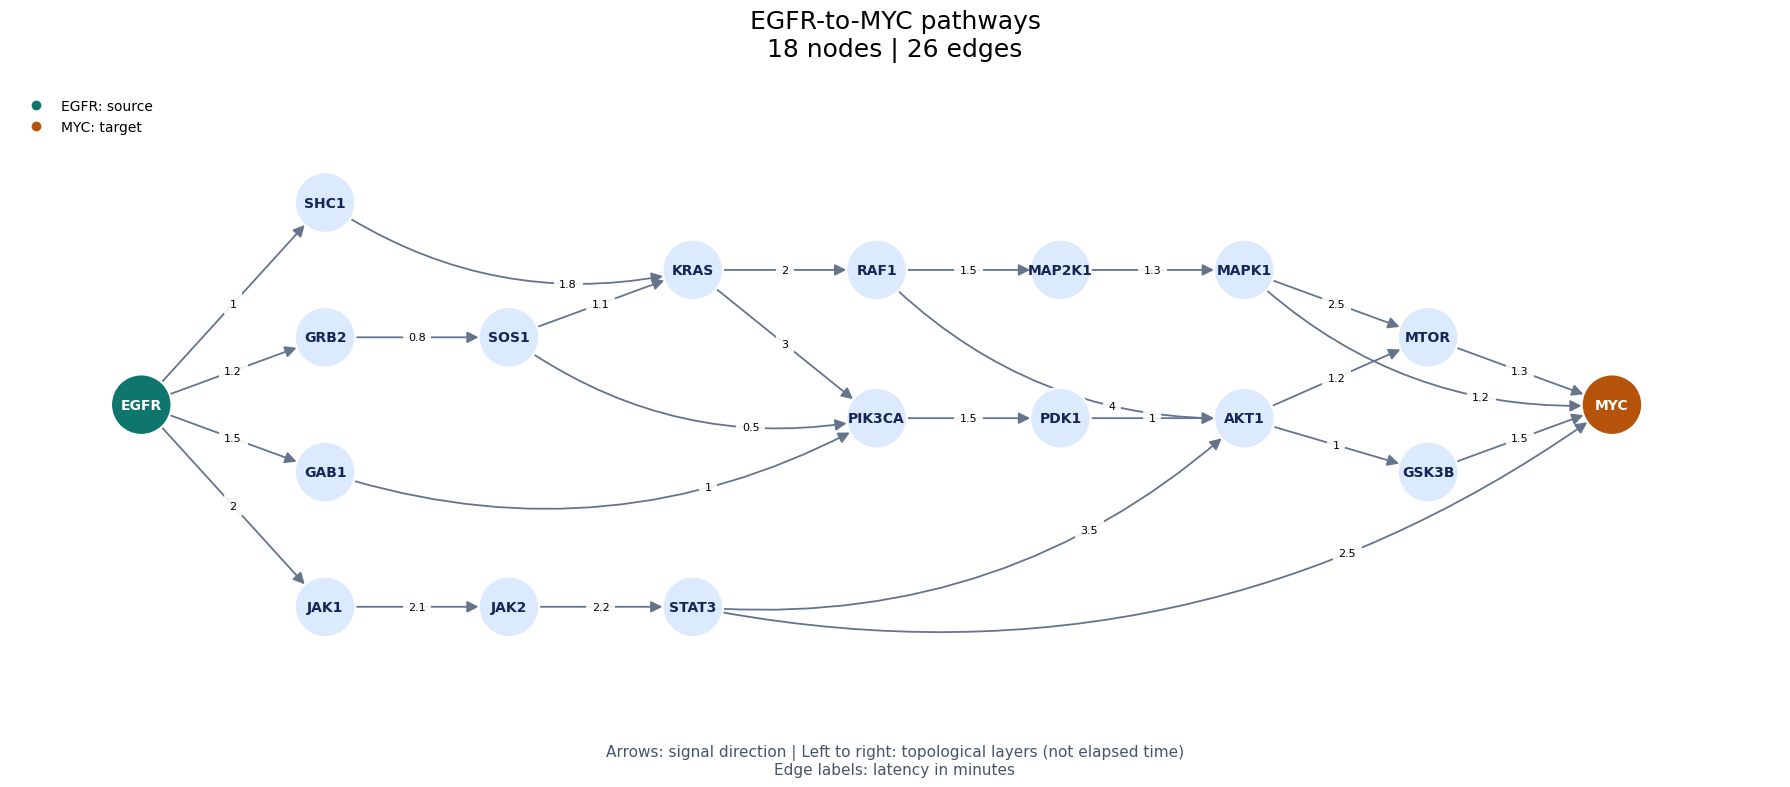

In [5]:
from visualize_network import plot_network
import matplotlib.pyplot as plt

fig, ax, graph = plot_network(
    "egfr_myc_large_network.csv",
    focus=True,
    show_weights=True,
    save_path="egfr_myc_network.png",
)

plt.show()



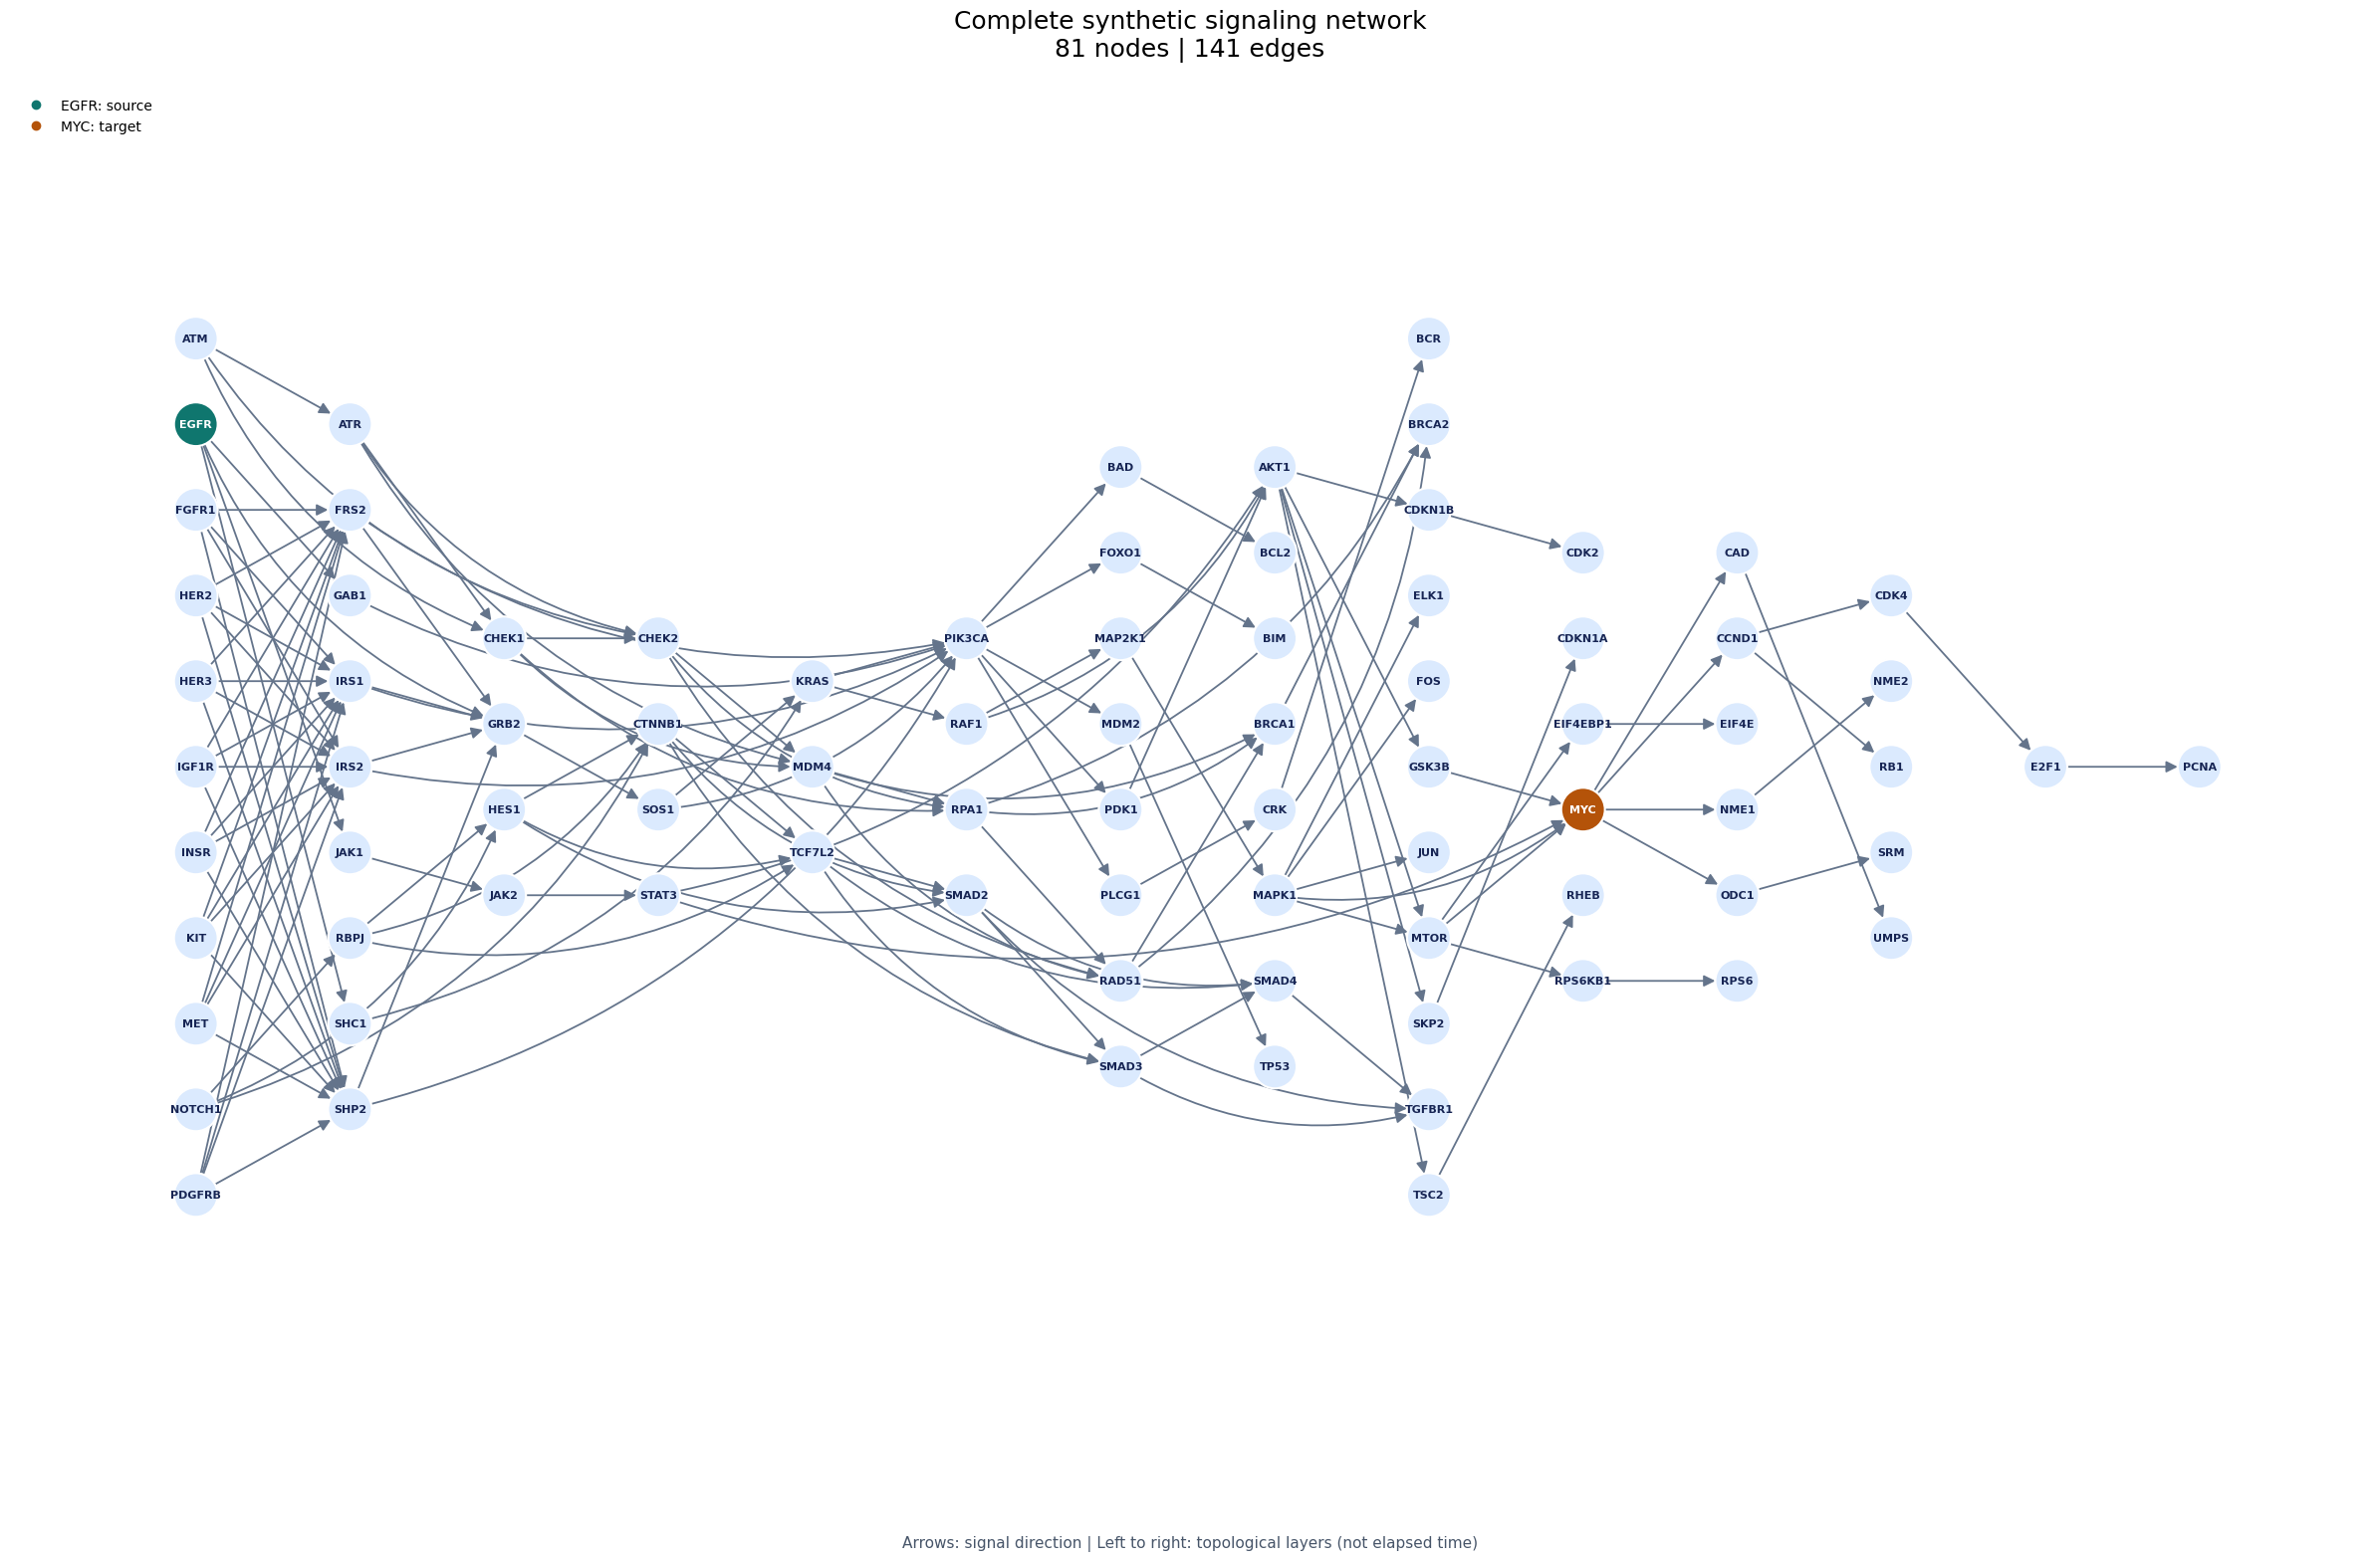

In [6]:
fig, ax, graph = plot_network(
    "egfr_myc_large_network.csv",
    focus=False,
    show_weights=False,
    save_path="full_network.png",
)

plt.show()

## Independent validation

The enumerator uses exact decimal sums and explicitly lists paths on these small graphs. It is a validation oracle, not the production DP algorithm.

In [7]:
from pathlib import Path
from validate_dp import enumerate_paths

all_paths = enumerate_paths(Path(csv_path).read_text())
best_latency = min(latency for latency, path in all_paths)
optimal_paths = sorted(path for latency, path in all_paths if latency == best_latency)
optimal_table = pd.DataFrame({
    "Path": [" -> ".join(path) for path in optimal_paths],
    "Latency (minutes)": [float(best_latency)] * len(optimal_paths),
})
optimal_table.to_csv("optimal_paths.csv", index=False)
print(f"All source-to-target paths: {len(all_paths)}")
print(f"Exact minimum latency: {best_latency} minutes")
print(f"Optimal paths: {len(optimal_paths)}")
assert len(optimal_paths) == result["co_optimal_path_count"]
assert sorted(set.intersection(*(set(path) for path in optimal_paths)) - {"EGFR", "MYC"}) == result["bottlenecks"]
optimal_table

All source-to-target paths: 19
Exact minimum latency: 7.5 minutes
Optimal paths: 4


,Path,Latency (minutes)
0,EGFR -> GAB1 -> PIK3CA -> PDK1 -> AKT1 -> GSK3...,7.5
1,EGFR -> GAB1 -> PIK3CA -> PDK1 -> AKT1 -> MTOR...,7.5
2,EGFR -> GRB2 -> SOS1 -> PIK3CA -> PDK1 -> AKT1...,7.5
3,EGFR -> GRB2 -> SOS1 -> PIK3CA -> PDK1 -> AKT1...,7.5


In [8]:
import unittest
import validate_dp

suite = unittest.defaultTestLoader.loadTestsFromModule(validate_dp)
validation = unittest.TextTestRunner(verbosity=2).run(suite)
assert validation.wasSuccessful() and not validation.skipped

test_branch_merge_and_dead_end (validate_dp.DPTests.test_branch_merge_and_dead_end) ... 

ok


test_course_dataset_and_row_order (validate_dp.DPTests.test_course_dataset_and_row_order) ... 

ok


test_cycle_rejected (validate_dp.DPTests.test_cycle_rejected) ... 

ok


... (13 outputs left out)

ok


test_unreachable_target (validate_dp.DPTests.test_unreachable_target) ... 

ok


----------------------------------------------------------------------
Ran 11 tests in 0.054s

OK


In [9]:
import hashlib
import json
import platform
import matplotlib
import networkx as nx

summary = {
    "dataset": Path(csv_path).name,
    "dataset_sha256": hashlib.sha256(Path(csv_path).read_bytes()).hexdigest(),
    "node_count": result["node_count"],
    "edge_count": result["edge_count"],
    "source": result["source"], "target": result["target"],
    "minimum_latency_minutes": result["min_latency"],
    "co_optimal_path_count": result["co_optimal_path_count"],
    "bottlenecks": result["bottlenecks"],
    "epsilon_minutes": dp_intro.EPSILON,
    "enumerated_path_count": len(all_paths),
    "validation_tests_run": validation.testsRun,
    "validation_tests_passed": validation.wasSuccessful(),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "matplotlib": matplotlib.__version__, "networkx": nx.__version__},
}
Path("results.json").write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n")
print(json.dumps(summary, indent=2))

{
  "dataset": "egfr_myc_large_network.csv",
  "dataset_sha256": "150ac54b98a7cb04170a4094b66362f97fbce70fb95396d78b94a86dad2a7746",
  "node_count": 81,
  "edge_count": 141,
  "source": "EGFR",
  "target": "MYC",
  "minimum_latency_minutes": 7.5,
  "co_optimal_path_count": 4,
  "bottlenecks": [
    "AKT1",
    "PDK1",
    "PIK3CA"
  ],
  "epsilon_minutes": 1e-06,
  "enumerated_path_count": 19,
  "validation_tests_run": 11,
  "validation_tests_passed": true,
  "versions": {
    "python": "3.13.5",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "networkx": "3.4.2"
  }
}


## Analytical questions


### 1. Experimental Results

```text
Minimum EGFR-to-MYC latency: 7.50 minutes
Co-optimal path count: 4
Bottleneck target genes: ['AKT1', 'PDK1', 'PIK3CA']
```

The four shortest paths combine two prefixes with two suffixes. The prefixes are `EGFR -> GAB1 -> PIK3CA` and `EGFR -> GRB2 -> SOS1 -> PIK3CA`, each taking 2.5 minutes. Both then traverse `PIK3CA -> PDK1 -> AKT1`, adding 2.5 minutes. Finally, either `AKT1 -> GSK3B -> MYC` or `AKT1 -> MTOR -> MYC` adds 2.5 minutes. The total is 7.5 minutes for all four combinations.

This view contains 18 nodes and 26 edges on any EGFR-to-MYC path, including slower alternatives. Arrows show direction; edge labels show minutes. Horizontal position follows dependency layers, not elapsed time. The [complete network view](full_network.png) also includes other sources, branches, and MYC downstream nodes.

PIK3CA, PDK1, and AKT1 lie on every shortest path, but not on every possible path. For example, `EGFR -> JAK1 -> JAK2 -> STAT3 -> MYC` takes 8.8 minutes and avoids all three. Their bottleneck status therefore does not imply that removing them eliminates every route to MYC.

### 2. Near-Optimal Signaling Dynamics (delta-Optimal Paths)

To count every path with total latency at most `D[MYC] + delta`, retain a distribution of path counts by accumulated latency at each node, rather than only its best distance and one count. Define `H[v][ell]` as the number of source-to-`v` paths with total latency `ell`. Initialize `H[EGFR][0] = 1` and all other states to zero. In topological order, propagate each state along each outgoing edge:

```text
budget = D[MYC] + delta
H[source][0] = 1
for u in topo_order:
    for (v, weight) in adj[u]:
        for (latency, count) in H[u]:
            new_latency = latency + weight
            if new_latency <= budget:
                H[v][new_latency] += count
answer = sum(H[MYC][latency] for latency <= budget)
```

This is a formulation, not an additional implemented solver. Positive weights make it safe to discard prefixes already exceeding the total budget. A further safe pruning rule uses a shortest remaining distance `d_to_target[v]`: discard a state if `new_latency + d_to_target[v] > budget`.

A single count loses the information needed to decide which prefixes remain feasible. For example, if two prefixes reach a node at 5.0 and 5.3 minutes and the remaining route costs 2.5 minutes, a total budget of 7.7 admits only the first. The ordinary shortest-path count discards the second prefix entirely, even though it would become eligible at a budget of 7.8. Simply increasing `EPSILON` cannot recover this missing distribution or enforce a total-path budget.

For this dataset, exact integer units of 0.01 minute are possible by parsing decimal weights and scaling them by 100. With budget index B = floor((D[MYC] + delta) / 0.01), a dense latency-state DP takes O(|E| B + |V| B) time and O(|V| B) space. This is pseudopolynomial in the numerical budget. For arbitrary real-valued weights, a sparse map of exact accumulated costs can have exponentially many distinct states; quantizing to bins controls size but introduces an approximation whose boundary effects must be stated. The extra state is accumulated latency (or equivalently remaining budget), not just path multiplicity.

### 3. Graph DP vs. Grid DP

Topological order and nested matrix loops both schedule subproblems so that every dependency is solved before it is used. In Smith-Waterman, cell `(i, j)` depends on `(i - 1, j)`, `(i, j - 1)`, and `(i - 1, j - 1)`; increasing row and column loops respect those dependencies. The grid itself therefore supplies an implicit topological order. The local-alignment zero reset changes the recurrence's values, not this scheduling requirement.

An arbitrary DAG has no regular row-column geometry. Kahn's algorithm constructs a legal order by repeatedly removing zero-remaining-in-degree nodes. Once all parents of `v` have contributed, `D[v]` and `C[v]` are final and can be used downstream. Reversing the same order makes successor-dependent quantities such as `R[v]` available before they are propagated upstream. Different valid orders give the same mathematical result; alphabetical names and initial in-degree values are not sufficient dependency schedules.

### 4. Biological Feedback Loops

With a directed cycle, Kahn's algorithm eventually exhausts its queue while some vertices remain unprocessed. Each node on the cycle still depends on another cycle node, so no complete topological order exists. The supplied implementation detects this by comparing the output-order length with the total node count and raises `ValueError`, even if the cycle is outside the EGFR-to-MYC region. A single DAG sweep cannot finalize values under circular dependencies.

Strictly positive edge weights still make the shortest distance well-defined for a reachable target in a finite graph: any walk containing a cycle can be shortened by deleting that positive-cost cycle, so a shortest route can be chosen among the finite set of simple paths. An unreachable target has distance infinity. Dijkstra's algorithm is an appropriate alternative for positive weights. After distances are known, exact shortest-path edges strictly increase distance, so they form an acyclic shortest-path subgraph on which counting can be performed. Positive cycles do not cause the unbounded distance decreases associated with negative cycles.


## Code evolution and design choices

I developed this exercise through repeated questions, explanations, and revisions. I started with the biological setting and the supplied starter code, then requested a minimum-latency implementation and notebook-ready examples. I asked for a visualization of the actual network and used it to work through how the forward sweep updates distances at branching and merging nodes. The focused EGFR-to-MYC view made these dependencies easier to follow, while the complete graph provided context.

I then requested path counting and asked how the update should change when a new route is shorter or equally short. I continued with questions about bottlenecks and a step-by-step explanation of reverse DP, including how `R[v]` accumulates and why `C[v] * R[v]` counts complete shortest paths through a node. These follow-up questions connected the code to concrete nodes such as PIK3CA, PDK1, and AKT1. With Codex assisting in code generation and revision, the implementation grew from a distance-only calculation into the complete forward/reverse analysis. A shared forward-sweep helper preserves the earlier notebook interfaces and avoids maintaining separate copies of the recurrence; the full node tables make the results inspectable.

The numerical precision guard follows the assignment. The near-optimal-path discussion uses a separate latency-state formulation because a biological timing allowance requires tracking accumulated costs. Input checks and explicit handling of unreachable targets make the implementation's assumptions clear, while exhaustive path enumeration provides a small-graph check of the DP results without replacing the scalable algorithm.

## AI assistance

I used OpenAI Codex as a coding and explanation assistant throughout an iterative question-and-revision process. I repeatedly asked about the biological background, the meaning of the DP variables, and how the calculations proceed on the actual network, then requested additions and adjustments to the code and notebook presentation. Codex helped translate these requests into Python code, revise the implementation, generate network figures, and express the analytical discussion.

I also used Codex to assist with automated validation, documentation, and repository organization. The progression of the exercise was shaped by my ongoing questions and requests, with code generation and refinement supported by Codex. I remain responsible for the submitted work and for being able to explain its reasoning.
